# De un producto a la búsqueda

Este notebook recorre el mismo camino que usa Lente:

1. arma el texto de un producto y descarga su foto
2. pide tres embeddings a Gemini: fusionado, solo texto y solo imagen
3. proyecta esos vectores a 2D con PCA
4. guarda los tres vectores (fusionado, texto e imagen) en una colección de prueba de Qdrant
5. embebe la consulta gafas de sol, la compara con los tres por similitud coseno y lo dibuja junto a los embeddings del producto
6. borra esa colección de prueba para poder repetir desde cero

Cohere sigue la misma forma sobre el vector nombrado cohere. Aquí usamos solo Gemini.

**Importante:** no toca la colección glasses de la tienda. Todo va a lente_walkthrough, con un namespace de ids distinto. Al final se elimina.

Corre desde ackend/ o ackend/notebooks/. Hace falta Qdrant en localhost:6333 y las claves en ackend/.env.


---

## Setup

Importa el backend, abre Gemini y Qdrant, y apunta a la colección de prueba.


In [37]:
import sys
import uuid
from pathlib import Path

ROOT = Path.cwd()
for candidate in (ROOT, ROOT.parent, ROOT / "backend", ROOT.parent / "backend"):
    if (candidate / "app").exists():
        BACKEND = candidate
        break
else:
    raise RuntimeError("Run this notebook from backend/ or from backend/notebooks/.")

sys.path.insert(0, str(BACKEND))

import httpx
import matplotlib.pyplot as plt
from qdrant_client import AsyncQdrantClient
from qdrant_client.http import models

from app.config import Settings
from app.domains.catalog.domain.pca import cosine, project
from app.domains.catalog.domain.product import Product, document_text
from app.domains.catalog.infrastructure.gemini_embedder import GeminiEmbedder
from app.ssl import use_system_certificates

use_system_certificates()

settings = Settings()
DEMO_COLLECTION = "lente_walkthrough"
# Separate from the storefront namespace so demo points never collide with glasses ids.
DEMO_NAMESPACE = uuid.UUID("a1b2c3d4-e5f6-7890-abcd-ef1234567890")

# Safe to re-run: close leftover clients from a previous pass.
if "http" in globals():
    try:
        await http.aclose()
    except Exception:
        pass
if "qdrant" in globals():
    try:
        await qdrant.close()
    except Exception:
        pass

http = httpx.AsyncClient(timeout=60.0, follow_redirects=True)
qdrant = AsyncQdrantClient(url=settings.qdrant_url)
gemini = GeminiEmbedder(settings, http)
print("backend", BACKEND)
print("store collection", settings.collection_name)
print("demo collection", DEMO_COLLECTION)
print("dimension", settings.embedding_dimension)


backend c:\Portfolio\embeddings_rag\episodio-1-intro-a-embeddings\backend
store collection glasses
demo collection lente_walkthrough
dimension 1536


---

## 1. Un producto del catálogo

Tomamos LN3548, unas gafas de sol. El texto que se embebe no es solo el nombre: document_text junta nombre, etiqueta de categoría y descripción. Ese string es el que entra al modelo junto con la foto.


Gafas De Sol Lente LN3548 Verde/Dorado. gafas de sol. Metal dorado. Forma redonda. Unisex. Lunas verdes, no polarizadas. Graduables.
image bytes 46380 image/jpeg


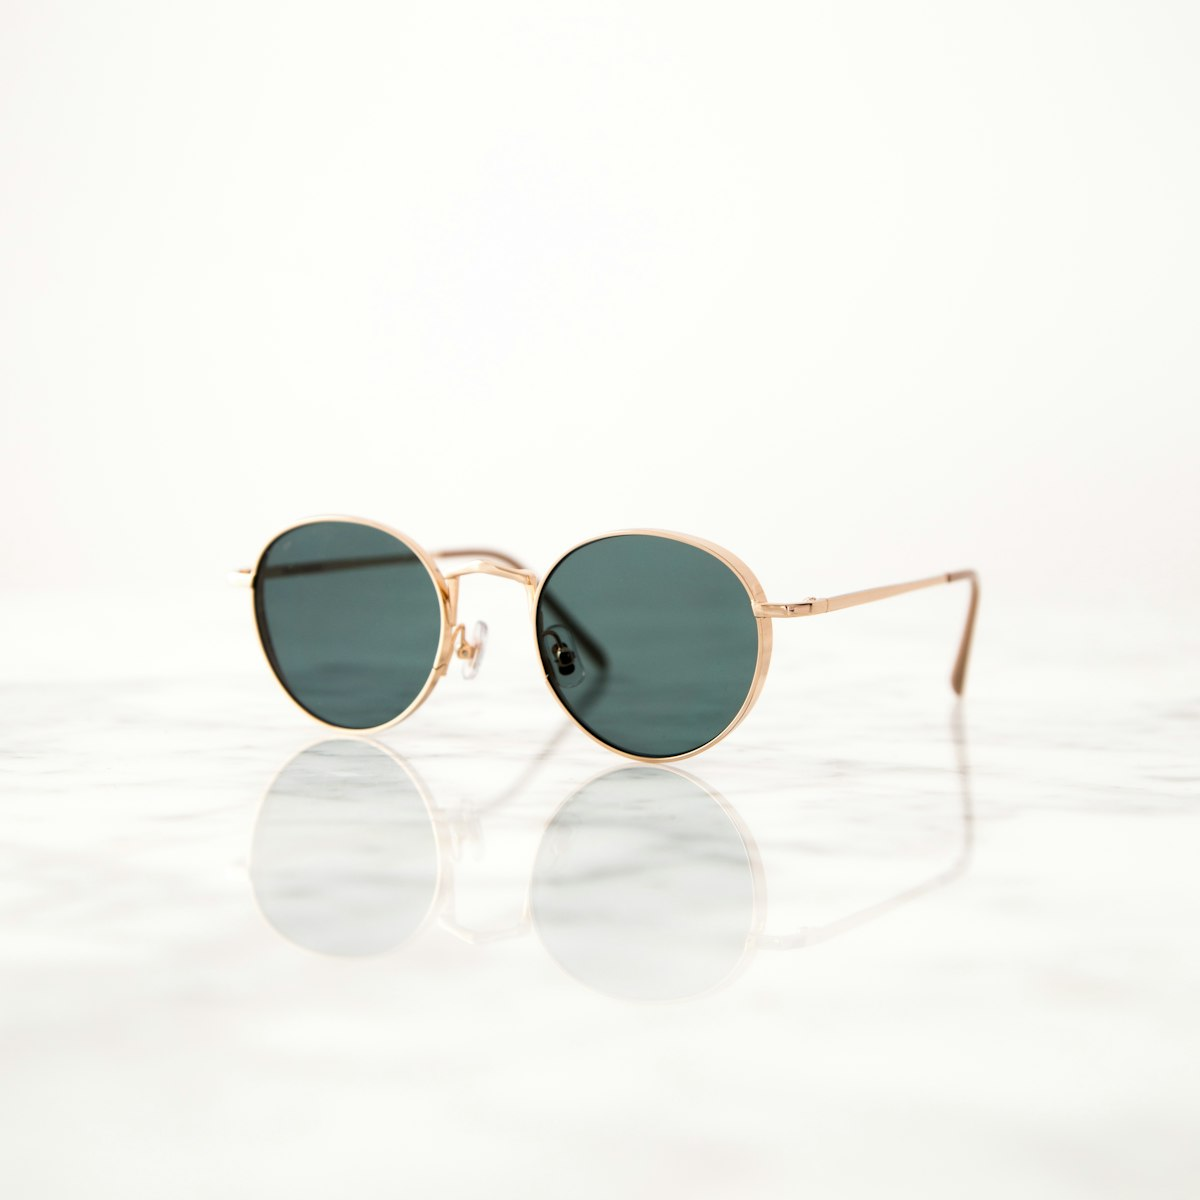

In [38]:
product = Product(
    id="demo-sol-aviador",
    name="Gafas De Sol Lente LN3548 Verde/Dorado",
    category="gafas",
    price=156,
    description="Metal dorado. Forma redonda. Unisex. Lunas verdes, no polarizadas. Graduables.",
    image_url="https://images.unsplash.com/photo-1511499767150-a48a237f0083?auto=format&fit=crop&w=1200&q=80",
)

text = document_text(product)
response = await http.get(product.image_url)
response.raise_for_status()
image = response.content
mime_type = response.headers.get("content-type", "image/jpeg").split(";")[0].strip()

from IPython.display import Image, display

print(text)
print("image bytes", len(image), mime_type)
display(Image(data=image, width=360))


---

## 2. Encoding

Gemini puede embeber texto, imagen, o **los dos juntos en una sola llamada**. Eso es el vector **fusionado**:

| Variable | Qué le pasas al modelo | Named vector en Qdrant |
|---|---|---|
| `fused` | texto **y** foto a la vez | `fused` |
| `text_only` | solo el texto del catálogo | `text` |
| `image_only` | solo la foto | `image` |

No es un promedio de dos vectores. El fusionado es **un** embedding de 1536 dims que el modelo arma mirando texto + imagen juntos. En este ejercicio los tres se guardan y la consulta se compara con cada uno.


In [39]:
fused = await gemini.embed_document(text, image, mime_type)
text_only = await gemini.embed_document_text(text)
image_only = await gemini.embed_document_image(image, mime_type)

def preview(name: str, vector: list[float]) -> None:
    """Print dimension and the first four floats."""
    head = ", ".join(f"{value:.4f}" for value in vector[:4])
    print(f"{name}: dim={len(vector)} head=[{head}, ...]")

preview("fused (text + image)", fused)
preview("text only", text_only)
preview("image only", image_only)


fused (text + image): dim=1536 head=[-0.0201, 0.0087, 0.0134, -0.0514, ...]
text only: dim=1536 head=[-0.0202, 0.0017, 0.0072, -0.0139, ...]
image only: dim=1536 head=[-0.0291, -0.0171, -0.0227, -0.0149, ...]


---

## Visualización 2D del producto

PCA reduce los vectores de 1536 dimensiones a dos ejes (PC1 y PC2). Tres puntos no alcanzan para un plano muy estable, pero alcanza para ver si el fusionado queda entre el texto y la imagen.


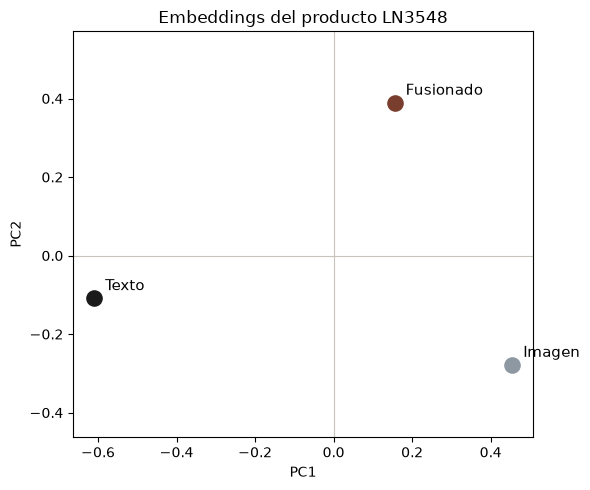

In [40]:
labels = ["Fusionado", "Texto", "Imagen"]
coords = project([fused, text_only, image_only])

fig, ax = plt.subplots(figsize=(6, 5))
colors = ["#7A3E2E", "#1A1A1A", "#8E98A3"]
for (label, (x, y, _)), color in zip(zip(labels, coords), colors):
    ax.scatter(x, y, s=120, color=color, zorder=3)
    ax.annotate(label, (x, y), textcoords="offset points", xytext=(8, 6), fontsize=11)

ax.axhline(0, color="#C9C4BB", linewidth=0.8)
ax.axvline(0, color="#C9C4BB", linewidth=0.8)
ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.set_title("Embeddings del producto LN3548")
ax.set_aspect("equal", adjustable="datalim")
fig.tight_layout()
plt.show()


---

## 3. Carga en Qdrant (colección de prueba)

Recrea `lente_walkthrough` desde cero y sube un solo punto con tres named vectors: `fused`, `text` e `image`. La consulta se busca contra cada uno por separado.

Después de ejecutar esta celda, abre el dashboard: [http://localhost:6333/dashboard](http://localhost:6333/dashboard). Deberías ver `lente_walkthrough` junto a `glasses`. **No corras la limpieza todavía** si quieres inspeccionarla.


In [41]:
VECTOR_NAMES = ("fused", "text", "image")

if await qdrant.collection_exists(DEMO_COLLECTION):
    await qdrant.delete_collection(DEMO_COLLECTION)

await qdrant.create_collection(
    collection_name=DEMO_COLLECTION,
    vectors_config={
        name: models.VectorParams(
            size=settings.embedding_dimension,
            distance=models.Distance.COSINE,
        )
        for name in VECTOR_NAMES
    },
)

point_id = str(uuid.uuid5(DEMO_NAMESPACE, product.id))
payload = product.to_dict()
stored = {"fused": fused, "text": text_only, "image": image_only}

await qdrant.upsert(
    collection_name=DEMO_COLLECTION,
    points=[
        models.PointStruct(
            id=point_id,
            vector=stored,
            payload=payload,
        )
    ],
    wait=True,
)

info = await qdrant.get_collection(DEMO_COLLECTION)
print("collection", DEMO_COLLECTION)
print("points", info.points_count)
print("upserted", product.id, point_id)
print("vectors", ", ".join(VECTOR_NAMES))
print("dashboard: http://localhost:6333/dashboard  — inspect before running Limpieza")


collection lente_walkthrough
points 1
upserted demo-sol-aviador d2262761-d793-5f8b-b9ef-8b6a725c6951
vectors fused, text, image
dashboard: http://localhost:6333/dashboard  — inspect before running Limpieza


---

## 4. Consulta y similitud

La búsqueda embebe `gafas de sol` con `search_query` y compara ese vector, por similitud coseno, con los tres que quedaron guardados. En esta colección solo hay un producto, así que cada búsqueda devuelve el mismo punto con un score distinto.


In [42]:
query = "gafas de sol"
query_vector = await gemini.embed_query(query, None, None)
preview("query", query_vector)

print()
print(f"query: {query!r}")
for vector_name in VECTOR_NAMES:
    result = await qdrant.query_points(
        collection_name=DEMO_COLLECTION,
        query=query_vector,
        using=vector_name,
        limit=1,
        with_payload=True,
    )
    hit = result.points[0]
    name = (hit.payload or {}).get("name", "")
    print(f"{vector_name:6}  {hit.score:.4f}  {name}")


query: dim=1536 head=[-0.0004, 0.0025, 0.0090, -0.0257, ...]

query: 'gafas de sol'
fused   0.6380  Gafas De Sol Lente LN3548 Verde/Dorado
text    0.4975  Gafas De Sol Lente LN3548 Verde/Dorado
image   0.6337  Gafas De Sol Lente LN3548 Verde/Dorado


---

## Visualización 2D con la consulta

Misma proyección PCA, ahora incluyendo el vector de la consulta. Cada línea punteada une la consulta con uno de los tres embeddings; el número es la similitud coseno en 1536 dimensiones.


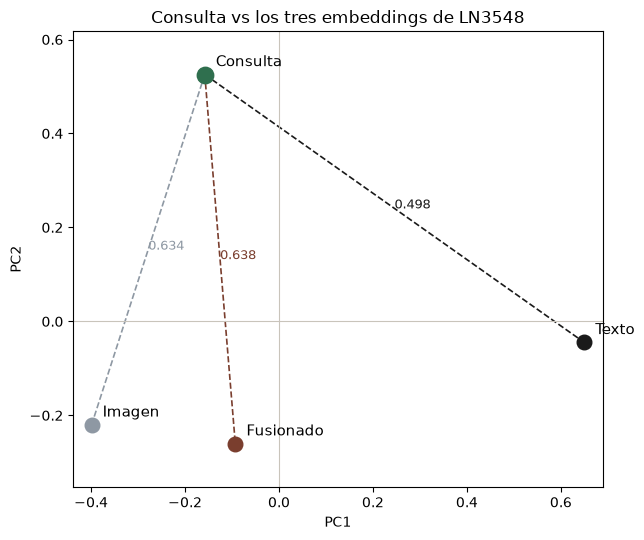

In [43]:
labels = ["Consulta", "Fusionado", "Texto", "Imagen"]
vectors = [query_vector, fused, text_only, image_only]
coords = project(vectors)
colors = ["#2F6F4E", "#7A3E2E", "#1A1A1A", "#8E98A3"]

fig, ax = plt.subplots(figsize=(6.5, 5.5))
for (label, (x, y, _)), color in zip(zip(labels, coords), colors):
    ax.scatter(x, y, s=140 if label == "Consulta" else 110, color=color, zorder=3)
    ax.annotate(label, (x, y), textcoords="offset points", xytext=(8, 6), fontsize=11)

qx, qy, _ = coords[0]
for (x, y, _), vector, color in zip(coords[1:], vectors[1:], colors[1:]):
    score = cosine(query_vector, vector)
    ax.plot([qx, x], [qy, y], color=color, linewidth=1.2, linestyle="--", zorder=2)
    ax.annotate(f"{score:.3f}", ((qx + x) / 2, (qy + y) / 2), fontsize=9, color=color)

ax.axhline(0, color="#C9C4BB", linewidth=0.8)
ax.axvline(0, color="#C9C4BB", linewidth=0.8)
ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.set_title("Consulta vs los tres embeddings de LN3548")
ax.set_aspect("equal", adjustable="datalim")
fig.tight_layout()
plt.show()


---

## Limpieza (opcional, al final)

Borra `lente_walkthrough`. La tienda (`glasses`) no se toca.

Corre esta celda **solo cuando ya miraste** la colección en el dashboard. Si la ejecutas antes, desaparece de Qdrant.

Los clientes quedan abiertos para otra pasada. Si ves `client has been closed`, vuelve a ejecutar **Setup**.


In [44]:
# if await qdrant.collection_exists(DEMO_COLLECTION):
#     await qdrant.delete_collection(DEMO_COLLECTION)
#     print("deleted", DEMO_COLLECTION)
# else:
#     print("already gone", DEMO_COLLECTION)

# print("clients still open — re-run from product (or Setup) for another pass")


---

## Cierre

- Documento: texto + foto → vector fusionado (search_document), más texto e imagen sueltos.
- Qdrant de prueba: un punto con tres named vectors (`fused`, `text`, `image`).
- Consulta: search_query → coseno contra cada uno de los tres.
- El plano 2D es solo una proyección: la similitud real sigue siendo el coseno en 1536 dimensiones.
